# Chapter 17: GPU & compute optimization

This notebook is the analysis half of the chapter. The VRAM and cost calculators run live. The
GPU measurements were produced by [`run_gpu_benchmarks.sh`](run_gpu_benchmarks.sh), which starts
llama-server, vLLM and Ollama one at a time on the RTX 3090 and writes `results/*.json` plus the
server logs in `results/logs/`. **The notebook reads those files; it does not launch servers**, so
it runs anywhere in a few seconds. Re-run the script on your own GPU to replace the numbers.

In [1]:
import json
import statistics
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import ch17_cost as cost
import ch17_vram as vram
from ch17_quant_bench import parse_vllm_log

RESULTS = Path("results")
IMAGES = Path("../images")
pd.set_option("display.width", 140)
print((RESULTS / "logs" / "environment.txt").read_text())

=== 2026-11-09T12:00:04+07:00 phases: ollama llama vllm
NVIDIA GeForce RTX 3090, 24576 MiB, 595.99.02
2093901, /home/t.estella/hd-face-gathering/venv/bin/python, 2322 MiB
vllm 0.33.0
torch 2.14.0+cu130 13.0
version: 0.9.0-dev (build 12182, commit fd27b2034)
ollama {"version":"0.40.15"}
=== 2026-11-09T12:11:40+07:00 phases: llama vllm
NVIDIA GeForce RTX 3090, 24576 MiB, 595.99.02
2093901, /home/t.estella/hd-face-gathering/venv/bin/python, 2324 MiB
vllm 0.33.0
torch 2.14.0+cu130 13.0
version: 0.9.0-dev (build 12182, commit fd27b2034)
ollama {"version":"0.40.15"}
=== 2026-11-09T12:25:24+07:00 phases: vllm_bf16 vllm_spec vllm_fp8
NVIDIA GeForce RTX 3090, 24576 MiB, 595.99.02
2093901, /home/t.estella/hd-face-gathering/venv/bin/python, 2324 MiB
vllm 0.33.0
torch 2.14.0+cu130 13.0
version: 0.9.0-dev (build 12182, commit fd27b2034)
ollama {"version":"0.40.15"}
=== 2026-11-09T13:37:40+07:00 phases: ollama vllm_awq
NVIDIA GeForce RTX 3090, 24576 MiB, 595.99.02
2093901, /home/t.estella/hd-face-ga

## 0. Which settings produced each result

Several phases ran more than once on 2026-11-09 (failed starts, then reruns with other memory
settings, and an Ollama + AWQ rerun after the ShopFlow database was reseeded). The JSON files
keep the latest successful result per label. The vLLM logs in
`results/logs/` are from the latest *start* of each configuration (including failed ones), and
their first lines record the arguments vLLM was given.

In [2]:
import re

settings = []
for log in sorted((RESULTS / "logs").glob("vllm-*.log")):
    text = log.read_text(errors="replace")
    args = re.search(r"non-default args: (\{.*\})", text)
    m_len = re.search(r"'max_model_len': (\d+)", args.group(1)) if args else None
    util = re.search(r"'gpu_memory_utilization': ([\d.]+)", args.group(1)) if args else None
    kv = re.search(r"GPU KV cache size: ([\d,]+) tokens", text)
    oom = "OutOfMemoryError" in text
    settings.append({"log": log.name,
                     "gpu_memory_utilization": float(util.group(1)) if util else None,
                     "max_model_len": int(m_len.group(1)) if m_len else None,
                     "kv_cache_tokens": int(kv.group(1).replace(",", "")) if kv else None,
                     "outcome": "CUDA OOM at startup" if oom else "served requests"})
pd.DataFrame(settings)

,log,gpu_memory_utilization,max_model_len,kv_cache_tokens,outcome
0,vllm-awq.log,0.80,16384,88624,served requests
1,vllm-bf16-noapc.log,0.80,14336,19488,served requests
2,vllm-bf16.log,0.80,12288,12912,served requests
3,vllm-draft-0.6b.log,0.84,2048,6048,served requests
4,vllm-eagle3.log,0.88,4096,15824,served requests
5,vllm-fp8.log,0.80,16384,59920,served requests
6,vllm-ngram.log,0.88,4096,32432,CUDA OOM at startup


## 1. Will it fit? The VRAM calculator

`ch17_vram.py` reads the Hugging Face `config.json` of each model (cached in `configs/`) and
applies two formulas: weights = parameters × bytes per parameter, and
KV cache = 2 × layers × KV heads × head dim × bytes × tokens × sequences.

In [3]:
specs = vram.load_all("configs")
rows = []
for name, s in specs.items():
    rows.append({
        "model": name,
        "params_B": round(vram.total_params(s) / 1e9, 2),
        "active_B": round(vram.active_params(s) / 1e9, 2),
        "layers": s.num_layers, "kv_heads": s.num_kv_heads, "head_dim": s.head_dim,
        "as_shipped_GiB": round(vram.weight_bytes(s) / vram.GIB, 1),
        "KV_KiB_per_token": round(vram.kv_bytes_per_token(s) / 1024, 1),
        "KV_GiB_32k": round(vram.kv_cache_bytes(s, 32_768) / vram.GIB, 2),
    })
pd.DataFrame(rows)

,model,params_B,active_B,layers,kv_heads,head_dim,as_shipped_GiB,KV_KiB_per_token,KV_GiB_32k
0,gpt-oss-120b,116.79,5.13,36,8,64,60.7,72.0,1.13
1,llama-3.3-70b,70.55,69.50,80,8,128,131.4,320.0,10.00
2,qwen3-1.7b,1.72,1.72,28,8,128,3.2,112.0,3.50
3,qwen3-8b,8.19,7.57,36,8,128,15.3,144.0,4.50


What fits on our card? The spec sheet says "24 GB"; `nvidia-smi` says 24,576 MiB, which is
25.77 GB. Another tenant's process holds about 2.3 GB of it, so the default vLLM budget in the run
script is 80% of the card (`--gpu-memory-utilization 0.80`).

In [4]:
GPU_GB = 24_576 * 2**20 / 1e9  # RTX 3090 as nvidia-smi reports it
UTIL = 0.80
fit = []
for name in ["qwen3-1.7b", "qwen3-8b", "llama-3.3-70b", "gpt-oss-120b"]:
    s = specs[name]
    for dt in ["bf16", "fp8", "q8_0", "q4_k_m", "int4"]:
        fit.append({
            "model": name, "weights": dt,
            "weights_GiB": round(vram.weight_bytes(s, dt) / vram.GIB, 1),
            "max_context_batch1": vram.max_context(s, GPU_GB, 1, dtype=dt, utilization=UTIL),
            "max_batch_at_4k": vram.max_batch(s, 4096, GPU_GB, dtype=dt, utilization=UTIL),
        })
fit_df = pd.DataFrame(fit)
fit_df[fit_df.model.isin(["qwen3-8b", "llama-3.3-70b"])]

,model,weights,weights_GiB,max_context_batch1,max_batch_at_4k
5,qwen3-8b,bf16,15.3,16619,4
6,qwen3-8b,fp8,7.6,72164,17
7,qwen3-8b,q8_0,8.1,68692,16
8,qwen3-8b,q4_k_m,4.6,94035,22
9,qwen3-8b,int4,3.8,99936,24
10,llama-3.3-70b,bf16,131.4,0,0
11,llama-3.3-70b,fp8,65.7,0,0
12,llama-3.3-70b,q8_0,69.8,0,0
13,llama-3.3-70b,q4_k_m,39.8,0,0
14,llama-3.3-70b,int4,32.9,0,0


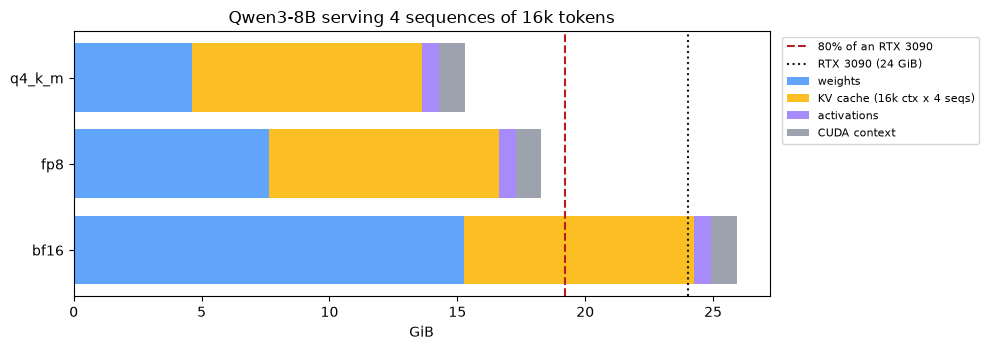

In [5]:
s = specs["qwen3-8b"]
fig, ax = plt.subplots(figsize=(10, 3.6))
labels, parts = [], {"weights": [], "KV cache (16k ctx x 4 seqs)": [], "activations": [],
                     "CUDA context": []}
for dt in ["bf16", "fp8", "q4_k_m"]:
    e = vram.estimate(s, 16_384, 4, dtype=dt)
    labels.append(dt)
    for k, v in zip(parts, [e.weights, e.kv_cache, e.activations, e.overhead]):
        parts[k].append(v / vram.GIB)
left = [0.0] * len(labels)
colors = ["#60a5fa", "#fbbf24", "#a78bfa", "#9ca3af"]
for (k, vals), c in zip(parts.items(), colors):
    ax.barh(labels, vals, left=left, label=k, color=c)
    left = [a + b for a, b in zip(left, vals)]
ax.axvline(GPU_GB * UTIL * 1e9 / vram.GIB, color="#b91c1c", ls="--", label="80% of an RTX 3090")
ax.axvline(GPU_GB * 1e9 / vram.GIB, color="#111827", ls=":", label="RTX 3090 (24 GiB)")
ax.set_xlabel("GiB")
ax.set_title("Qwen3-8B serving 4 sequences of 16k tokens")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1))
fig.tight_layout()
fig.savefig(IMAGES / "17-vram-qwen3-8b.png", dpi=150)
plt.show()

### The calculator against vLLM's own accounting

vLLM profiles memory at startup and logs what it found. We compare that with the calculator.

In [6]:
logs = {"Qwen/Qwen3-8B (bf16)": ("vllm-bf16.log", "bf16"),
        "Qwen/Qwen3-8B-AWQ (int4)": ("vllm-awq.log", "int4"),
        "RedHatAI/Qwen3-8B-FP8-dynamic": ("vllm-fp8.log", "fp8")}
cmp = []
for label, (fname, dt) in logs.items():
    seen = parse_vllm_log((RESULTS / "logs" / fname).read_text(errors="replace"))
    predicted_kv_tokens = seen["kv_cache_gib"] * vram.GIB / vram.kv_bytes_per_token(s)
    cmp.append({
        "model": label,
        "weights_GiB_calc": round(vram.weight_bytes(s, dt) / vram.GIB, 2),
        "weights_GiB_vllm": seen["weights_gib"],
        "kv_GiB_vllm": seen["kv_cache_gib"],
        "kv_tokens_calc_from_kv_GiB": int(predicted_kv_tokens),
        "kv_tokens_vllm": seen["kv_cache_tokens"],
    })
pd.DataFrame(cmp)

,model,weights_GiB_calc,weights_GiB_vllm,kv_GiB_vllm,kv_tokens_calc_from_kv_GiB,kv_tokens_vllm
0,Qwen/Qwen3-8B (bf16),15.26,15.27,1.77,12888,12912
1,Qwen/Qwen3-8B-AWQ (int4),3.81,5.71,12.17,88619,88624
2,RedHatAI/Qwen3-8B-FP8-dynamic,7.63,8.80,8.23,59929,59920


## 2. Why decode speed is about bandwidth: the roofline

At batch 1, every generated token reads every weight once. Bandwidth / bytes of weights is the
speed limit. The RTX 3090 has 936 GB/s (NVIDIA GA102 whitepaper).

In [7]:
quant = json.loads((RESULTS / "quant.json").read_text())
prices = cost.load_prices()
BW = prices["gpu_memory_bandwidth_gb_s"]["RTX 3090 24GB"]
dtype_of = {"ollama-q4_K_M": "q4_k_m", "ollama-q8_0": "q8_0", "ollama-fp16": "fp16",
            "vllm-bf16": "bf16", "vllm-awq-int4": "int4", "vllm-fp8-w8a16": "fp8"}
roof = []
for cfg, r in quant.items():
    ceiling = cost.decode_roofline(s, BW, dtype=dtype_of[cfg]).tokens_per_second
    roof.append({"config": cfg, "roofline_tok_s": round(ceiling, 1),
                 "measured_tok_s": r["decode_tok_s"],
                 "pct_of_roofline": round(100 * r["decode_tok_s"] / ceiling, 1)})
roof_df = pd.DataFrame(roof)
roof_df

,config,roofline_tok_s,measured_tok_s,pct_of_roofline
0,ollama-q4_K_M,188.5,130.1,69.0
1,ollama-q8_0,107.6,89.0,82.7
2,ollama-fp16,57.1,53.1,92.9
3,vllm-awq-int4,228.6,128.3,56.1
4,vllm-bf16,57.1,48.9,85.6
5,vllm-fp8-w8a16,114.3,87.0,76.1


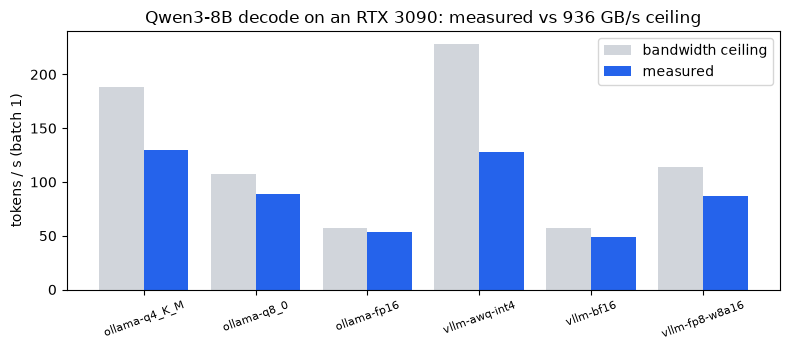

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = range(len(roof_df))
ax.bar([i - 0.2 for i in x], roof_df.roofline_tok_s, 0.4, label="bandwidth ceiling",
       color="#d1d5db")
ax.bar([i + 0.2 for i in x], roof_df.measured_tok_s, 0.4, label="measured", color="#2563eb")
ax.set_xticks(list(x), roof_df.config, rotation=20, fontsize=8)
ax.set_ylabel("tokens / s (batch 1)")
ax.set_title("Qwen3-8B decode on an RTX 3090: measured vs 936 GB/s ceiling")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES / "17-roofline.png", dpi=150)
plt.show()

## 3. Quantization: speed, memory and accuracy on the Chapter 2 eval

300 tickets (all 60 hard ones + 240 seeded templated ones), strict JSON schema, temperature 0,
one request at a time.

In [9]:
qdf = pd.DataFrame([{
    "config": k, "weights": r["weights"],
    "category_acc": r["category_acc"], "ci95": r["category_ci95"],
    "priority_acc": r["priority_acc"], "hard_cat_acc": r["hard_category_acc"],
    "parse_fail": r["parse_failures"], "p50_ms": r["latency_p50_ms"],
    "p95_ms": r["latency_p95_ms"], "decode_tok_s": r["decode_tok_s"],
    "memory": r["memory"].get("vram_gb") or r["memory"].get("weights_gib"),
} for k, r in quant.items()])
qdf

,config,weights,category_acc,ci95,priority_acc,hard_cat_acc,parse_fail,p50_ms,p95_ms,decode_tok_s,memory
0,ollama-q4_K_M,GGUF q4_K_M,79.0,"[74.0, 83.2]",62.7,83.3,0,421,484,130.1,9.94
1,ollama-q8_0,GGUF q8_0,80.7,"[75.8, 84.7]",57.3,81.7,0,596,698,89.0,13.25
2,ollama-fp16,GGUF f16,79.3,"[74.4, 83.5]",57.7,81.7,0,970,1140,53.1,20.09
3,vllm-awq-int4,AWQ int4,84.7,"[80.2, 88.3]",60.7,81.7,0,421,478,128.3,5.71
4,vllm-bf16,bf16,80.3,"[75.5, 84.4]",58.0,81.7,0,1067,1256,48.9,15.27
5,vllm-fp8-w8a16,FP8 (W8A16),80.3,"[75.5, 84.4]",57.3,81.7,0,586,705,87.0,8.80


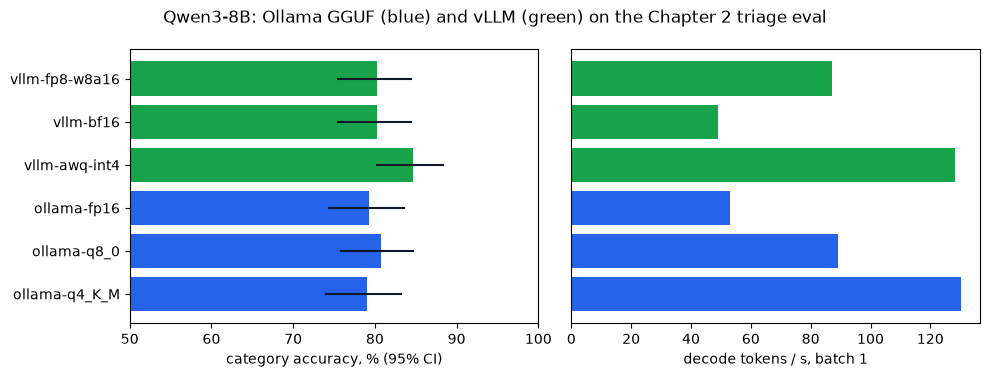

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
colors = ["#2563eb" if c.startswith("ollama") else "#16a34a" for c in qdf.config]
axes[0].barh(qdf.config, qdf.category_acc, color=colors)
for i, (lo, hi) in enumerate(qdf.ci95):
    axes[0].plot([lo, hi], [i, i], color="#111827")
axes[0].set_xlim(50, 100)
axes[0].set_xlabel("category accuracy, % (95% CI)")
axes[1].barh(qdf.config, qdf.decode_tok_s, color=colors)
axes[1].set_xlabel("decode tokens / s, batch 1")
axes[1].set_yticks([])
fig.suptitle("Qwen3-8B: Ollama GGUF (blue) and vLLM (green) on the Chapter 2 triage eval")
fig.tight_layout()
fig.savefig(IMAGES / "17-quantization.png", dpi=150)
plt.show()

Do the configurations disagree on the *same* tickets? The number of the 300 predicted categories
that differ between each pair of runs:

In [11]:
by_id = {k: {x["id"]: x for x in r["rows"]} for k, r in quant.items()}
names = list(by_id)
pd.DataFrame([[sum(by_id[a][i].get("category") != by_id[b][i].get("category")
                   for i in by_id[a]) for b in names] for a in names],
             index=names, columns=names)

,ollama-q4_K_M,ollama-q8_0,ollama-fp16,vllm-awq-int4,vllm-bf16,vllm-fp8-w8a16
ollama-q4_K_M,0,7,3,19,6,6
ollama-q8_0,7,0,4,12,7,5
ollama-fp16,3,4,0,16,5,3
vllm-awq-int4,19,12,16,0,13,13
vllm-bf16,6,7,5,13,0,2
vllm-fp8-w8a16,6,5,3,13,2,0


And of the tickets where a configuration disagrees with bf16, how often was bf16 the one that
was right?

In [12]:
ref = by_id["vllm-bf16"]
flips = pd.DataFrame([{
    "config": k,
    "differs_from_bf16": sum(by_id[k][i].get("category") != ref[i].get("category") for i in ref),
    "bf16_right": sum(by_id[k][i].get("category") != ref[i].get("category")
                      and ref[i]["category_ok"] for i in ref),
    "config_right": sum(by_id[k][i].get("category") != ref[i].get("category")
                        and by_id[k][i]["category_ok"] for i in ref),
} for k in names])
flips

,config,differs_from_bf16,bf16_right,config_right
0,ollama-q4_K_M,6,5,1
1,ollama-q8_0,7,3,4
2,ollama-fp16,5,4,1
3,vllm-awq-int4,13,0,13
4,vllm-bf16,0,0,0
5,vllm-fp8-w8a16,2,1,1


## 4. Batching: aggregate throughput on vLLM

In [13]:
tp = []
for k, r in quant.items():
    for t in r.get("throughput", []):
        tp.append({"config": k, **t})
tp_df = pd.DataFrame(tp)
tp_df

,config,concurrency,output_tokens,wall_s,output_tok_s,per_stream_tok_s
0,vllm-awq-int4,1,256,2.02,126.6,127.0
1,vllm-awq-int4,8,2048,2.17,944.2,119.6
2,vllm-awq-int4,32,8192,3.40,2411.6,77.4
3,vllm-bf16,1,256,5.31,48.2,48.4
4,vllm-bf16,8,2048,5.42,378.0,47.6
5,vllm-bf16,32,8192,6.31,1298.8,41.5
6,vllm-fp8-w8a16,1,256,2.91,88.1,88.4
7,vllm-fp8-w8a16,8,2048,3.08,665.1,84.0
8,vllm-fp8-w8a16,32,8192,3.73,2196.2,70.5


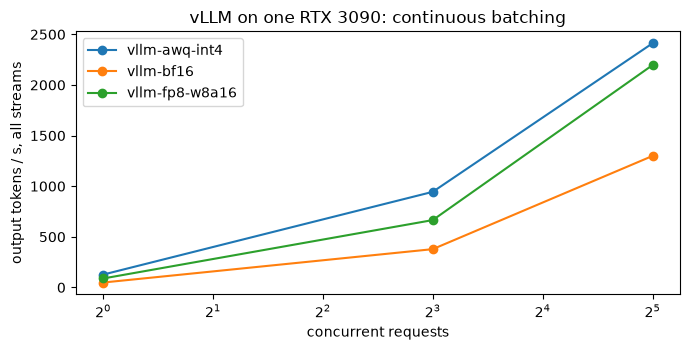

In [14]:
fig, ax = plt.subplots(figsize=(7, 3.6))
for k, g in tp_df.groupby("config"):
    ax.plot(g.concurrency, g.output_tok_s, marker="o", label=k)
ax.set_xscale("log", base=2)
ax.set_xlabel("concurrent requests")
ax.set_ylabel("output tokens / s, all streams")
ax.set_title("vLLM on one RTX 3090: continuous batching")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES / "17-batching.png", dpi=150)
plt.show()

## 5. Prefix caching: time to first token

In [15]:
prefix = json.loads((RESULTS / "prefix.json").read_text())
pdf = pd.DataFrame([{
    "engine": v["engine"], "prefix_chars": v["prefix_chars"], "scenario": v["scenario"],
    "prompt_tokens": v["prompt_tokens"], "first_ttft_ms": v["first_ttft_ms"],
    "later_median_ttft_ms": v["later_median_ttft_ms"],
    "server_cached_2nd": v["rows"][1]["server_cached"] if len(v["rows"]) > 1 else None,
} for v in prefix.values()])
pdf

,engine,prefix_chars,scenario,prompt_tokens,first_ttft_ms,later_median_ttft_ms,server_cached_2nd
0,llama,12000,cache off,2788,609.1,606.6,0
1,llama,12000,"cache on, stable prefix",2788,607.6,22.4,2773
2,llama,12000,"cache on, timestamp at start",2789,608.1,720.0,0
3,llama,48000,cache off,10883,2767.4,2775.4,0
4,llama,48000,"cache on, stable prefix",10883,2784.3,36.0,10868
5,llama,48000,"cache on, timestamp at start",10884,2789.7,3149.6,0
6,vllm,12000,cache off,2788,669.8,671.3,0
7,vllm,48000,cache off,10883,2984.7,3004.5,0
8,vllm,12000,"cache on, stable prefix",2788,700.9,39.2,2768
9,vllm,12000,"cache on, timestamp at start",2789,702.0,703.2,16


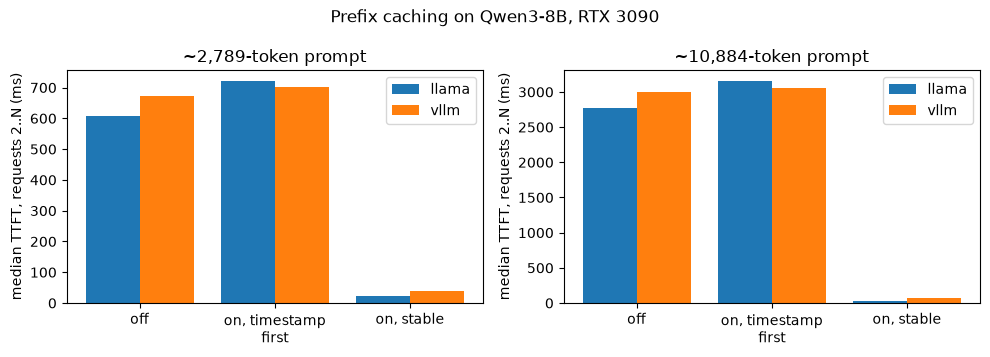

In [16]:
order = ["cache off", "cache on, timestamp at start", "cache on, stable prefix"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=False)
for ax, chars in zip(axes, sorted(pdf.prefix_chars.unique())):
    sub = pdf[pdf.prefix_chars == chars]
    for j, eng in enumerate(["llama", "vllm"]):
        vals = [sub[(sub.engine == eng) & (sub.scenario == sc)].later_median_ttft_ms.squeeze()
                for sc in order]
        ax.bar([i + 0.4 * j for i in range(3)], vals, 0.4, label=eng)
    toks = int(sub.prompt_tokens.max())
    ax.set_xticks([i + 0.2 for i in range(3)], ["off", "on, timestamp\nfirst", "on, stable"])
    ax.set_title(f"~{toks:,}-token prompt")
    ax.set_ylabel("median TTFT, requests 2..N (ms)")
    ax.legend()
fig.suptitle("Prefix caching on Qwen3-8B, RTX 3090")
fig.tight_layout()
fig.savefig(IMAGES / "17-prefix-cache.png", dpi=150)
plt.show()

## 6. Speculative decoding

In [17]:
spec = json.loads((RESULTS / "spec.json").read_text())
base = {"llama": spec["llama/baseline"], "vllm": spec["vllm/baseline"]}
sdf = []
for label, by_c in spec.items():
    eng = label.split("/")[0]
    for c, r in by_c.items():
        b = base[eng][c] if c in base[eng] else None
        sdf.append({"label": label, "concurrency": int(c),
                    "median_stream_tok_s": r["median_stream_tok_s"],
                    "aggregate_tok_s": r["aggregate_tok_s"],
                    "speedup_vs_baseline": round(r["median_stream_tok_s"]
                                                 / b["median_stream_tok_s"], 2) if b else None,
                    "acceptance": r["acceptance"]})
sdf = pd.DataFrame(sdf)
sdf

,label,concurrency,median_stream_tok_s,aggregate_tok_s,speedup_vs_baseline,acceptance
0,llama/baseline,1,130.2,121.7,1.00,NaN
1,llama/draft-0.6b,1,125.9,118.6,0.97,NaN
2,vllm/ngram,1,57.5,56.2,1.18,0.047
3,vllm/ngram,8,39.2,297.1,0.82,0.047
4,vllm/baseline,1,48.8,47.4,1.00,NaN
5,vllm/baseline,8,47.9,366.5,1.00,NaN
6,vllm/eagle3,1,126.5,103.5,2.59,0.535
7,vllm/eagle3,8,107.6,712.1,2.25,0.526
8,vllm/draft-0.6b,1,122.1,81.6,2.50,0.473
9,vllm/draft-0.6b,8,94.1,500.8,1.96,0.480


In [18]:
per_prompt = []
for label, by_c in spec.items():
    for r in by_c["1"]["rows"]:
        per_prompt.append({"label": label, "prompt": r["prompt"],
                           "tok_s": r["client_decode_tok_s"]})
pp = pd.DataFrame(per_prompt).pivot(index="prompt", columns="label", values="tok_s")
pp

label,llama/baseline,llama/draft-0.6b,vllm/baseline,vllm/draft-0.6b,vllm/eagle3,vllm/ngram
prompt,,,,,,
code_edit,127.15,123.65,48.79,137.74,126.51,122.89
freeform_1,130.20,122.30,48.80,79.72,93.67,48.30
freeform_2,123.39,123.28,48.40,76.83,106.83,48.64
freeform_3,123.44,125.89,47.78,64.49,103.76,49.50
json_triage_1,134.02,126.30,49.74,122.10,128.71,58.94
json_triage_2,133.98,126.36,49.98,127.21,129.64,57.46
json_triage_3,132.00,128.21,49.72,130.33,144.36,63.01


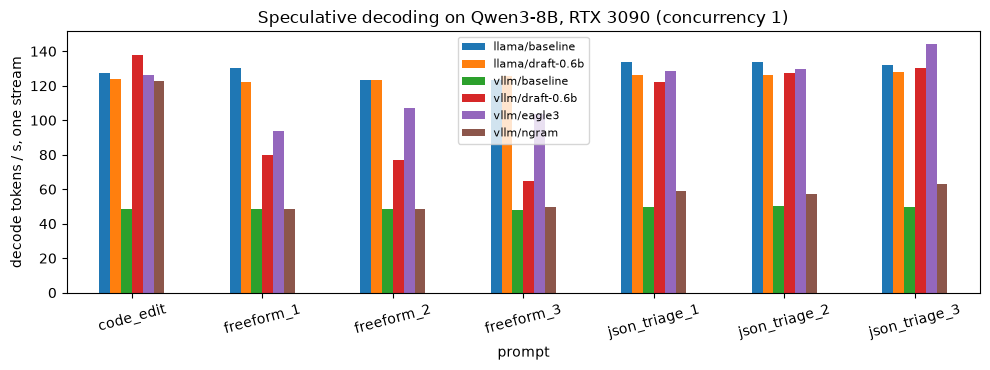

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.8))
pp.plot.bar(ax=ax, rot=15)
ax.set_ylabel("decode tokens / s, one stream")
ax.set_title("Speculative decoding on Qwen3-8B, RTX 3090 (concurrency 1)")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(IMAGES / "17-speculative.png", dpi=150)
plt.show()

Greedy decoding should give the same text with and without speculation. Does it?

In [20]:
for eng in ["llama", "vllm"]:
    b = {r["prompt"]: r["text"] for r in spec[f"{eng}/baseline"]["1"]["rows"]}
    for label in [k for k in spec if k.startswith(eng + "/") and not k.endswith("baseline")]:
        same = sum(r["text"] == b[r["prompt"]] for r in spec[label]["1"]["rows"])
        print(f"{label:20s} identical text on {same}/{len(b)} prompts")

llama/draft-0.6b     identical text on 7/7 prompts
vllm/ngram           identical text on 6/7 prompts
vllm/eagle3          identical text on 6/7 prompts
vllm/draft-0.6b      identical text on 6/7 prompts


## 7. What does a million tokens cost?

Measured throughput on our card, priced at RunPod's RTX 3090 rate, next to published H100 numbers
and API prices. Prices are dated in `gpu_prices.json`.

In [21]:
runpod = prices["gpu_hourly_usd"]["RunPod Secure Cloud (on-demand; page updated 2026-11-04)"]
community = prices["gpu_hourly_usd"]["RunPod Community Cloud (on-demand; page updated 2026-11-04)"]
rows = []
for _, t in tp_df.iterrows():
    for util in (1.0, 0.3):
        rows.append({"setup": f"{t.config} on 1x RTX 3090, {t.concurrency} streams",
                     "tok_s": t.output_tok_s, "utilization": util,
                     "usd_per_M_secure": round(cost.cost_per_million_tokens(
                         runpod["RTX 3090 24GB"], 1, t.output_tok_s, util), 4),
                     "usd_per_M_community": round(cost.cost_per_million_tokens(
                         community["RTX 3090 24GB"], 1, t.output_tok_s, util), 4)})
for name, m in prices["measured_throughput"].items():
    gpu = "H100 SXM 80GB"
    rows.append({"setup": name + " (published)", "tok_s": m["output_tokens_per_second"],
                 "utilization": 1.0,
                 "usd_per_M_secure": round(cost.cost_per_million_tokens(
                     runpod[gpu], m["n_gpus"], m["output_tokens_per_second"]), 4),
                 "usd_per_M_community": round(cost.cost_per_million_tokens(
                     community[gpu], m["n_gpus"], m["output_tokens_per_second"]), 4)})
cost_df = pd.DataFrame(rows)
cost_df

,setup,tok_s,utilization,usd_per_M_secure,usd_per_M_community
0,"vllm-awq-int4 on 1x RTX 3090, 1 streams",126.60,1.0,1.0971,0.4827
1,"vllm-awq-int4 on 1x RTX 3090, 1 streams",126.60,0.3,3.6569,1.6090
2,"vllm-awq-int4 on 1x RTX 3090, 8 streams",944.20,1.0,0.1471,0.0647
3,"vllm-awq-int4 on 1x RTX 3090, 8 streams",944.20,0.3,0.4903,0.2157
4,"vllm-awq-int4 on 1x RTX 3090, 32 streams",2411.60,1.0,0.0576,0.0253
5,"vllm-awq-int4 on 1x RTX 3090, 32 streams",2411.60,0.3,0.1920,0.0845
6,"vllm-bf16 on 1x RTX 3090, 1 streams",48.20,1.0,2.8815,1.2679
7,"vllm-bf16 on 1x RTX 3090, 1 streams",48.20,0.3,9.6050,4.2262
8,"vllm-bf16 on 1x RTX 3090, 8 streams",378.00,1.0,0.3674,0.1617
9,"vllm-bf16 on 1x RTX 3090, 8 streams",378.00,0.3,1.2248,0.5389


In [22]:
api = prices["api_usd_per_million_tokens"]
api_df = pd.DataFrame([{"model": k, "input": v["input"], "output": v["output"],
                        "blended_75pct_input": round(cost.blended_api_price(v["input"],
                                                                            v["output"]), 4)}
                       for k, v in api.items() if not k.startswith("_")])
api_df

,model,input,output,blended_75pct_input
0,openai/gpt-oss-120b,0.02,0.075,0.0338
1,meta-llama/llama-3.3-70b-instruct,0.59,0.790,0.6400
2,qwen/qwen3-14b,0.12,0.240,0.1500
3,openai/gpt-6-luna,0.10,0.500,0.2000


In [23]:
best = tp_df.sort_values("output_tok_s").iloc[-1]
for model in ["qwen/qwen3-14b", "openai/gpt-6-luna"]:
    u = cost.breakeven_utilization(runpod["RTX 3090 24GB"], 1, best.output_tok_s,
                                   api[model]["output"])
    print(f"{best.config} at {best.output_tok_s} tok/s on a $"
          f"{runpod['RTX 3090 24GB']}/h RTX 3090 vs {model} output price "
          f"${api[model]['output']}/M: break-even utilization = {u if u is None else round(u, 3)}")

vllm-awq-int4 at 2411.6 tok/s on a $0.5/h RTX 3090 vs qwen/qwen3-14b output price $0.24/M: break-even utilization = 0.24
vllm-awq-int4 at 2411.6 tok/s on a $0.5/h RTX 3090 vs openai/gpt-6-luna output price $0.5/M: break-even utilization = 0.115
